<a href="https://colab.research.google.com/github/merveenoyan/smol-vision/blob/main/qlora_click_grounding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Supervised Fine-Tuning (SFT) Muse Glimmer with QLoRA using TRL — GUI click/pointing grounding

![trl banner](https://huggingface.co/datasets/trl-lib/documentation-images/resolve/main/trl_banner_dark.png)

With [**Transformers Reinforcement Learning (TRL)**](https://github.com/huggingface/trl), you can fine-tune cutting edge vision-language models. It comes with support for the quantized parameter-efficient fine-tuning technique **QLoRA**.

This notebook fine-tunes a **Muse Glimmer** vision-language checkpoint on the [**merve/MolmoWeb-mini**](https://huggingface.co/datasets/merve/MolmoWeb-mini) dataset for a **GUI click/pointing grounding** task: given a screenshot and a natural-language instruction (e.g. *"search for help button"*), the model must predict where on the screen to click.

This example shows how to do vision fine-tuning as well as teaching model to do structured output better. Resulting model (when trained on more examples) can be paired with GUI agentic harnesses for computer use.

We will:

1. Hold out screenshots that are **never** used for training, and measure the base model's zero-shot click accuracy on them (in 4-bit).
2. QLoRA fine-tune on the remaining screenshots.
3. Re-run the same held-out eval set on the fine-tuned model and compare.

- [TRL GitHub Repository](https://github.com/huggingface/trl) — star us to support the project!
- [TRL SFTTrainer docs — training vision-language models](https://huggingface.co/docs/trl/en/sft_trainer#training-vision-language-models)

In [ ]:
!pip install -Uq transformers==5.15.0
!pip install -q "trl[peft]" bitsandbytes accelerate datasets trackio pillow

In [2]:
import bitsandbytes as bnb
import peft
import torch
import transformers
import trl

In [3]:
import os

model_id = "meta-models/muse-glimmer-30b"
OUTPUT_DIR = "/content/lora"

SEED = 0
MAX_MESSAGES_PER_TRAIN_IMAGE =  5
IMAGE_MAX_SIDE = 512

REASONING_STRENGTH = "low"

os.makedirs(OUTPUT_DIR, exist_ok=True)

## Load dataset

**MolmoWeb-mini** contains screenshots of real websites. Each screenshot contains a list of independent `(question, answer, thought, bbox)` tuples: `question` is a natural-language instruction, `answer` is the target model output, a JSON string with a `thought` and a `click` `action` (`x`, `y` as a **percentage of image width/height**) and `bbox` is the ground-truth clickable region in pixels of the original image.

We ran these examples across 100 images and compared model fine-tuned on MolmoWeb format against base model zero-shot outputs converted to MolmoWeb format. We found that base model has 13% click accuracy + 35.0% within 5% diagonal while fine-tuned model has 41% + 68% within 5% diagonal.

In [ ]:
from datasets import load_dataset

raw_dataset = load_dataset("merve/MolmoWeb-mini", split="train").shuffle(seed=SEED).train_test_split(test_size=0.1)

test_rows = raw_dataset["test"]
train_rows = raw_dataset["train"]

print(f"total screenshots:         {len(raw_dataset)}")
print(f"held-out test screenshots: {len(test_rows)}")
print(f"train screenshots:    {len(train_rows)}")

Let's review one example to understand the internal structure:

columns: ['image', 'messages', 'metadata']
metadata: {'website': 'allrecipes', 'url': 'https://www.allrecipes.com/recipe/174543/slow-cooker-butter-chicken/', 'image_w': 1288, 'image_h': 712}
instructions on this screenshot: 5
first instruction: jump to the Nutrition Facts section
first target answer: {"thought": "I will click the 'Jump to Nutrition Facts' button near the top of the page to scroll directly to that section.", "action": {"name": "click", "button": "left", "click_type": "single", "x": 32.7, "y": 2.3}}


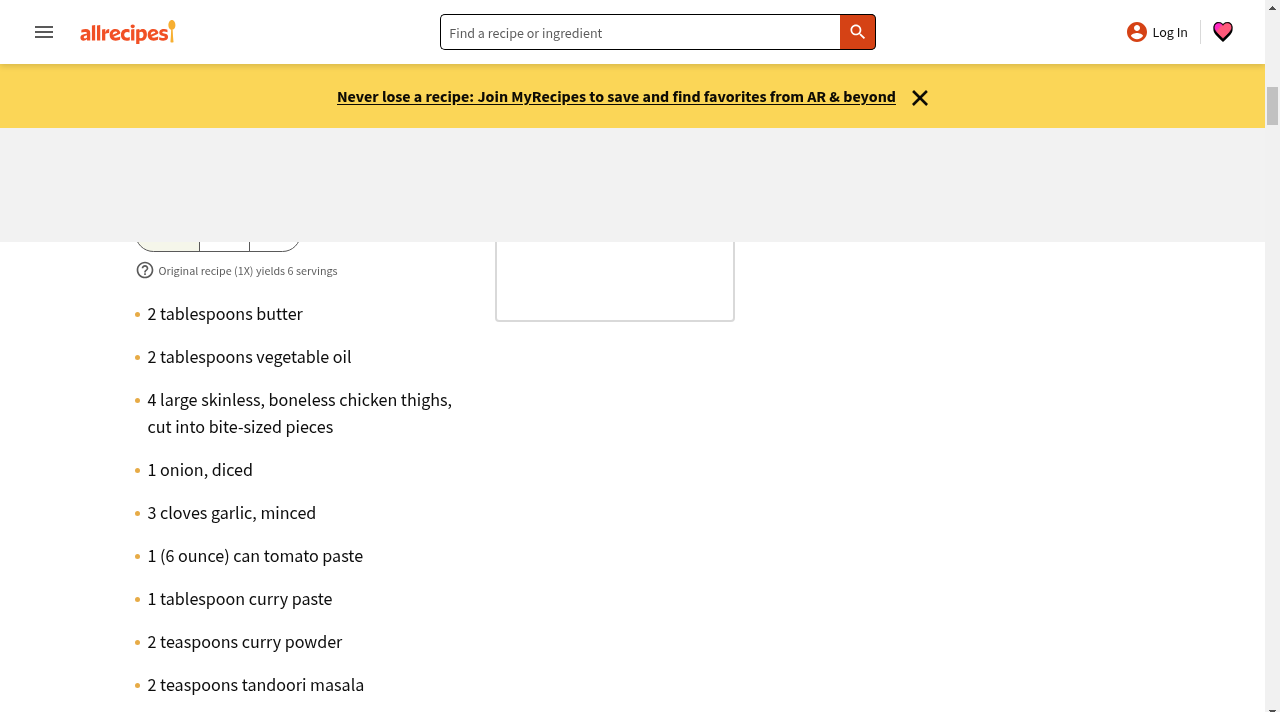

In [ ]:
example_row = train_rows[0]
print("columns:", list(example_row.keys()))
print("metadata:", example_row["metadata"])
print("instructions on this screenshot:", len(example_row["messages"]))
print("first instruction:", example_row["messages"][0]["question"])
print("first target answer:", example_row["messages"][0]["answer"])
example_row["image"]

## Build the click/pointing conversational format

For each screenshot we sample a few of its instructions (up to `MAX_MESSAGES_PER_TRAIN_IMAGE` for training, exactly 1 for eval so the held-out set stays diverse across distinct screenshots) and turn each `(image, question, answer)` triple into a two-turn conversation. We reuse the dataset's `answer` field as the assistant target.

Screenshots are downsized before being fed to the model to keep sequence length and memory in check. Because the target coordinates are *percentages*, this resize does not change the labels — one of the practical reasons to prefer a percentage convention over absolute pixels.

In [5]:
import random

from PIL import Image

CLICK_INSTRUCTION_TEMPLATE = (
    "You are looking at a screenshot of a webpage. Follow this instruction: {question}\n\n"
    "Respond with a single JSON object of the form "
    '{{"thought": "<brief reasoning>", "action": {{"name": "click", "button": "left", '
    '"click_type": "single", "x": <0-100>, "y": <0-100>}}}}, '
    "where x and y are the click point as a percentage of the image width and height. "
    "Output only the JSON object."
)


def resize_image(image, max_side):
    image = image.convert("RGB")
    image.thumbnail((max_side, max_side), Image.Resampling.LANCZOS)
    return image


def flatten_rows(rows, seed, max_messages_per_image):
    rng = random.Random(seed)
    flat = []
    for row in rows:
        meta = row["metadata"]
        messages = row["messages"]
        indices = list(range(len(messages)))
        rng.shuffle(indices)
        for i in indices[:max_messages_per_image]:
            m = messages[i]
            flat.append(
                {
                    "image": row["image"],
                    "question": m["question"],
                    "answer": m["answer"],
                    "bbox": m["bbox"],
                    "image_w": meta["image_w"],
                    "image_h": meta["image_h"],
                }
            )
    return flat


train_pool = flatten_rows(train_rows, seed=SEED, max_messages_per_image=MAX_MESSAGES_PER_TRAIN_IMAGE)
random.Random(SEED).shuffle(train_pool)

eval_pool = flatten_rows(test_rows, seed=SEED, max_messages_per_image=1)[:100]


Convert the flattened training examples into the conversational multimodal format that `SFTTrainer`'s vision-language collator expects: an `"images"` list plus a `"messages"` list.

In [ ]:
from datasets import Dataset


def to_conversation(example):
    image = resize_image(example["image"], IMAGE_MAX_SIDE)
    instruction = CLICK_INSTRUCTION_TEMPLATE.format(question=example["question"])
    return {
        "images": [image],
        "messages": [
            {"role": "user", "content": [{"type": "image"}, {"type": "text", "text": instruction}]},
            {"role": "assistant", "content": [{"type": "text", "text": example["answer"]}]},
        ],
    }


train_dataset = Dataset.from_list([to_conversation(ex) for ex in train_pool])
print(train_dataset)
train_dataset[0]["messages"]

## Map out coordinates before comparing

We found out that the model answers in **three different conventions**, sometimes mixing two in a single object:

- pixels in the original image
- pixels in the resized image it was shown
- percentage of image size (what we actually asked for)

Ground truth is pixels in the original image, so predictions must be mapped out into that space. The rule below picks the unit from the prediction and image only.

We also report distance-based accuracy, not just strict bbox containment as some clicks can be on large buttons.

In [19]:
import json
import math
import re
import time


def extract_to_user(decoded_with_special_tokens):
    """Return the assistant's `to=user` message, or None if it never reached that channel."""
    protocol = "<|start|>assistant" + decoded_with_special_tokens
    matches = re.findall(
        r"<\|start\|>assistant to=user<\|message\|>(.*?)(?=<\|eot\|>|<\|eom\|>|$)",
        protocol,
        flags=re.DOTALL,
    )
    return matches[-1].strip() if matches else None


def parse_click(text):
    """Pull the last "x"/"y" pair out of the answer."""
    xs = re.findall(r'"x"\s*:\s*(-?\d+(?:\.\d+)?)', text)
    ys = re.findall(r'"y"\s*:\s*(-?\d+(?:\.\d+)?)', text)
    if not xs or not ys:
        return None
    return float(xs[-1]), float(ys[-1])


def map_out(x, y, orig_w, orig_h):
    """Map a raw (x, y) prediction into original-image pixels. Returns (px, py, unit_label)."""
    scale = min(IMAGE_MAX_SIDE / orig_w, IMAGE_MAX_SIDE / orig_h, 1.0)
    if x > 100 or y > 100:
        if x <= orig_w * scale and y <= orig_h * scale:
            return x / scale, y / scale, "pixels_resized"
        return x, y, "pixels_original"
    return x / 100 * orig_w, y / 100 * orig_h, "percent"


def grade(pred, bbox_str, orig_w, orig_h):
    px, py, unit = map_out(pred[0], pred[1], orig_w, orig_h)
    x0, y0, x1, y1 = (float(v) for v in json.loads(bbox_str))
    hit = x0 <= px <= x1 and y0 <= py <= y1
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    dist = math.hypot(px - cx, py - cy)
    return {
        "unit": unit,
        "canonical_xy": (px, py),
        "click_in_bbox": hit,
        "dist_to_center_px": dist,
        "dist_frac_of_diagonal": dist / math.hypot(orig_w, orig_h),
    }

### Evaluation loop

In [7]:
def evaluate_click_grounding(model, processor, examples, label, batch_size=None):
    batch_size = batch_size or 12
    was_training = model.training
    model.eval()
    model.config.use_cache = True
    torch.cuda.reset_peak_memory_stats()

    images, texts = [], []
    for ex in examples:
        image = resize_image(ex["image"], IMAGE_MAX_SIDE)
        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image", "image": image},
                    {"type": "text", "text": CLICK_INSTRUCTION_TEMPLATE.format(question=ex["question"])},
                ],
            }
        ]
        images.append([image])
        texts.append(
            processor.apply_chat_template(
                messages,
                add_generation_prompt=True,
                tokenize=False,
                reasoning_strength=REASONING_STRENGTH,
            )
        )

    decoded_all, token_counts = [], []
    wall_start = time.perf_counter()
    for start in range(0, len(texts), batch_size):
        inputs = processor(
            images=images[start : start + batch_size],
            text=texts[start : start + batch_size],
            padding=True,
            padding_side="left",
            return_tensors="pt",
            add_special_tokens=False,
        ).to(model.device)
        prompt_len = inputs["input_ids"].shape[-1]
        with torch.inference_mode():
            out = model.generate(
                **inputs,
                max_new_tokens=1024,
                do_sample=False,
            )
        torch.cuda.synchronize()
        gen = out[:, prompt_len:]
        decoded_all.extend(processor.batch_decode(gen, skip_special_tokens=False))
        token_counts.extend(
            int((gen[i] != processor.tokenizer.pad_token_id).sum()) for i in range(gen.shape[0])
        )
        print(f"  [{label}] generated {len(decoded_all)}/{len(texts)}", flush=True)
    wall_seconds = time.perf_counter() - wall_start

    records = []
    for ex, decoded, n_tok in zip(examples, decoded_all, token_counts):
        answer = extract_to_user(decoded)
        pred = parse_click(answer) if answer else None
        rec = {
            "question": ex["question"],
            "answer": answer,
            "pred": pred,
            "bbox": ex["bbox"],
            "reached_to_user": answer is not None,
            "generated_tokens": n_tok,
        }
        if pred:
            rec.update(grade(pred, ex["bbox"], ex["image_w"], ex["image_h"]))
        records.append(rec)

    graded = [r for r in records if r.get("pred")]
    n = len(records)
    dists = sorted(r["dist_frac_of_diagonal"] for r in graded)
    unit_mix = {}
    for r in graded:
        unit_mix[r["unit"]] = unit_mix.get(r["unit"], 0) + 1

    summary = {
        "label": label,
        "num_examples": n,
        "reach_to_user_rate": sum(r["reached_to_user"] for r in records) / n,
        "parse_rate": len(graded) / n,
        "click_accuracy": sum(r["click_in_bbox"] for r in graded) / n,
        "within_5pct_diagonal": sum(1 for d in dists if d <= 0.05) / n,
        "within_10pct_diagonal": sum(1 for d in dists if d <= 0.10) / n,
        "within_20pct_diagonal": sum(1 for d in dists if d <= 0.20) / n,
        "median_dist_frac_of_diagonal": dists[len(dists) // 2] if dists else None,
        "mean_generated_tokens": sum(token_counts) / n,
}
    model.train(was_training)
    return summary, records

## Load model and configure LoRA/QLoRA

We load the Muse Glimmer in 4-bit (NF4, double quantization, bf16 compute dtype to match both the checkpoint and the H100's native precision).

In [ ]:
from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig

processor = AutoProcessor.from_pretrained("meta-models/muse-glimmer-30b")

model = AutoModelForMultimodalLM.from_pretrained(
    "meta-models/muse-glimmer-30b",
    dtype=torch.bfloat16,
    device_map="auto",
    quantization_config=BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True,
        bnb_4bit_quant_type="nf4",
        llm_int8_skip_modules=["model.vision_tower", "model.vision_adapter", "lm_head"], # we do not quantize vision
    ),
)

print(f"total parameters: {sum(p.numel() for p in model.parameters()):,}")

We evaluate baseline model performance in 4-bit.

In [ ]:
baseline_summary, baseline_records = evaluate_click_grounding(
    model, processor, eval_pool, label="baseline (zero-shot, 4-bit)"
)
print(json.dumps(baseline_summary, indent=2))

with open(os.path.join(OUTPUT_DIR, "baseline_eval.json"), "w") as f:
    json.dump({"summary": baseline_summary, "records": baseline_records}, f, indent=2, default=str)

[transformers] You have used a torchvision backend image processor with LANCZOS resample which is not supported for torch.Tensor with torchvision < 0.27. BICUBIC resample will be used as an alternative. Please upgrade torchvision to 0.27+ or fall back to a pil backend image processor if you want full consistency with the original model.
[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [baseline (zero-shot, 4-bit)] generated 12/100


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [baseline (zero-shot, 4-bit)] generated 24/100


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

  [baseline (zero-shot, 4-bit)] generated 84/100


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [baseline (zero-shot, 4-bit)] generated 96/100


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [baseline (zero-shot, 4-bit)] generated 100/100
{
  "label": "baseline (zero-shot, 4-bit)",
  "num_examples": 100,
  "reach_to_user_rate": 1.0,
  "parse_rate": 1.0,
  "click_accuracy": 0.01,
  "within_5pct_diagonal": 0.11,
  "within_10pct_diagonal": 0.23,
  "within_20pct_diagonal": 0.63,
  "median_dist_frac_of_diagonal": 0.16646833521802198,
  "mean_generated_tokens": 283.86
}


Here's the output (there's a repeating warning that clutters output a bit):
```
{
  "label": "baseline (zero-shot, 4-bit)",
  "num_examples": 60,
  "reach_to_user_rate": 1.0,
  "parse_rate": 0.7,
  "click_accuracy": 0.0333,
  "within_5pct_diagonal": 0.1,
  "within_10pct_diagonal": 0.183,
  "within_20pct_diagonal": 0.266,
  "median_dist_frac_of_diagonal": 0.258,
}
```

We need to exclude some modules from quantization. Muse Glimmer's vision tower reuses the exact same `q_proj`/`k_proj`/`v_proj`/`o_proj` names as the text decoder, so we explicitly `exclude_modules`, otherwise LoRA would attach adapters inside the (unquantized, frozen) vision encoder too.

In [ ]:
from peft import LoraConfig

peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    exclude_modules=".*vision_tower.*",
)

We need to subclass data collator for two reasons:

1. Completion-only loss: TRL doesn't do prompt masking on vision, so we need to do it ourselves.
2. Prompt consistency: TRL's collator calls `processor.apply_chat_template(messages)` with no extra kwargs (`chat_template_kwargs` (this exists for text-only fine-tuning but not image) We need to pass in `reasoning_strength`, so without this the training prompts would render at the template default (`"high"`) which makes model output a ton of tokens without outputting anything meaningful.

In [ ]:
from trl.data_utils import prepare_multimodal_messages
from trl.trainer.sft_trainer import DataCollatorForVisionLanguageModeling


RESPONSE_HEADER = "<|start|>assistant to=user<|message|>"


class MuseGlimmerVisionCollator(DataCollatorForVisionLanguageModeling):
    """Vision collator with completion-only loss and a fixed `reasoning_strength`."""

    def __init__(self, processor, **kwargs):
        super().__init__(processor, **kwargs)
        self.response_header_ids = processor.tokenizer(RESPONSE_HEADER, add_special_tokens=False)["input_ids"]

    def _collate_language_modeling(self, examples):
        images = [example["images"] for example in examples]
        messages = [
            prepare_multimodal_messages(example["messages"], images=example["images"]) for example in examples
        ]
        texts = self.processor.apply_chat_template(messages, reasoning_strength=REASONING_STRENGTH)

        output = self.processor(
            images=images,
            text=texts,
            padding=True,
            padding_side="right",
            pad_to_multiple_of=self.pad_to_multiple_of,
            truncation=self.max_length is not None,
            max_length=self.max_length,
            return_tensors=self.return_tensors,
            add_special_tokens=False,
        )
        labels = output["input_ids"].clone()
        labels[output["attention_mask"] == 0] = -100

        for row in range(labels.shape[0]):
            ids = output["input_ids"][row].tolist()
            cut = None
            for start in range(len(ids) - len(self.response_header_ids) + 1):
                if ids[start : start + len(self.response_header_ids)] == self.response_header_ids:
                    cut = start + len(self.response_header_ids)
            if cut is None:
                raise RuntimeError("assistant response header not found; cannot apply completion-only loss")
            labels[row, :cut] = -100
        output["labels"] = labels
        return output

## Train model

`SFTConfig` is set up for a demo-scale run (we only train for 500 steps). See the [TRL `SFTConfig` docs](https://huggingface.co/docs/trl/sft_trainer#trl.SFTConfig) for every option.

In [ ]:
from trl import SFTConfig

training_args = SFTConfig(
    max_steps=500,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    warmup_steps=5,
    learning_rate=5e-5,
    optim="adamw_8bit",
    max_length=None,
    bf16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    output_dir=OUTPUT_DIR,
    logging_steps=5,
    push_to_hub=True,
    report_to="trackio",
    run_name="qlora-clicking-2",
    seed=SEED,
)

Configure the SFT Trainer with the already-quantized `model`, the `peft_config` (which `SFTTrainer` uses to wrap the model in LoRA adapters), the `processor` as `processing_class`, and our prompt-consistent collator.

In [ ]:
from trl import SFTTrainer

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    processing_class=processor,
    peft_config=peft_config,
    data_collator=MuseGlimmerVisionCollator(processor),
)
trainer.model.print_trainable_parameters()

In [ ]:
trainer.train()

## Post-training evaluation

We now evaluate the model against the set we held out and ran our baseline evaluations against.

In [ ]:
final_summary, final_records = evaluate_click_grounding(
    trainer.model, processor, eval_pool, label="fine-tuned (QLoRA, 4-bit)"
)
print(json.dumps(final_summary, indent=2))

with open(os.path.join(OUTPUT_DIR, "final_eval.json"), "w") as f:
    json.dump({"summary": final_summary, "records": final_records}, f, indent=2, default=str)

[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [fine-tuned (QLoRA, 4-bit)] generated 12/100


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [fine-tuned (QLoRA, 4-bit)] generated 24/100


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

  [fine-tuned (QLoRA, 4-bit)] generated 84/100


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [fine-tuned (QLoRA, 4-bit)] generated 96/100


[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [fine-tuned (QLoRA, 4-bit)] generated 100/100
{
  "label": "fine-tuned (QLoRA, 4-bit)",
  "num_examples": 100,
  "reach_to_user_rate": 0.95,
  "parse_rate": 0.95,
  "click_accuracy": 0.45,
  "within_5pct_diagonal": 0.76,
  "within_10pct_diagonal": 0.82,
  "within_20pct_diagonal": 0.88,
  "median_dist_frac_of_diagonal": 0.018721278765276787,
  "mean_generated_tokens": 126.97
}


```
{
  "label": "fine-tuned (QLoRA, 4-bit)",
  "num_examples": 100,
  "reach_to_user_rate": 0.95,
  "parse_rate": 0.95,
  "click_accuracy": 0.45,
  "within_5pct_diagonal": 0.76,
  "within_10pct_diagonal": 0.82,
  "within_20pct_diagonal": 0.88,
  "median_dist_frac_of_diagonal": 0.018721278765276787,
  "mean_generated_tokens": 126.97
}
```

In [12]:
from peft import PeftModel
from transformers import AutoModelForMultimodalLM

base_model = AutoModelForMultimodalLM.from_pretrained("meta-models/Muse-Glimmer-30B")
processor = AutoProcessor.from_pretrained("meta-models/Muse-Glimmer-30B")
model = PeftModel.from_pretrained(base_model, "merve/muse-glimmer-ft-clicking-v2").to("cuda")

Loading weights:   0%|          | 0/1436 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/peft/config.py:220: UserWarning: Unexpected keyword arguments ['monteclora_config', 'velora_config'] for class LoraConfig, these are ignored. This probably means that you're loading a configuration file that was saved using a higher version of the library and additional parameters have been introduced since. It is highly recommended to upgrade the PEFT version before continuing (e.g. by running `pip install -U peft`).
  warnings.warn(


adapter_model.safetensors: reconstructing file:   0%|          |  0.00B / 58.8MB            

adapter_model.safetensors: downloading bytes:           |  0.00B            

In [16]:
model=model.to("cuda")

In [17]:
from PIL import ImageDraw


def predict_and_show(example):
    image = resize_image(example["image"], IMAGE_MAX_SIDE)
    messages = [{"role": "user", "content": [
        {"type": "image", "image": image},
        {"type": "text", "text": CLICK_INSTRUCTION_TEMPLATE.format(question=example["question"])},
    ]}]
    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
        reasoning_strength=REASONING_STRENGTH,
    ).to(model.device) #to(trainer.model.device)

    with torch.inference_mode():
        out = model.generate(**inputs, max_new_tokens=1024, do_sample=False)
    decoded = processor.batch_decode(out[:, inputs["input_ids"].shape[-1] :])[0]
    answer = extract_to_user(decoded)
    print(example["question"], "->", answer)

    canvas = example["image"].convert("RGB")
    draw = ImageDraw.Draw(canvas)
    draw.rectangle(json.loads(example["bbox"]), outline="lime", width=3)

    pred = parse_click(answer) if answer else None
    if pred:
        x, y, unit = map_out(*pred, example["image_w"], example["image_h"])
        draw.ellipse([x - 18, y - 18, x + 18, y + 18], outline="red", width=3)
        draw.ellipse([x - 5, y - 5, x + 5, y + 5], fill="red", outline="white", width=2)
        print(f"click ({x:.0f}, {y:.0f}) read as {unit}")
    return canvas

[transformers] Both `max_new_tokens` (=1024) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


open the Force Factor Creatine HMB page via the title link -> {"thought": "The title link for the second product is in the grid. I will click it to open the product page.", "action": {"name": "click", "button": "left", "click_type": "single", "x": 40.3, "y": 31.0}}
click (519, 221) read as percent


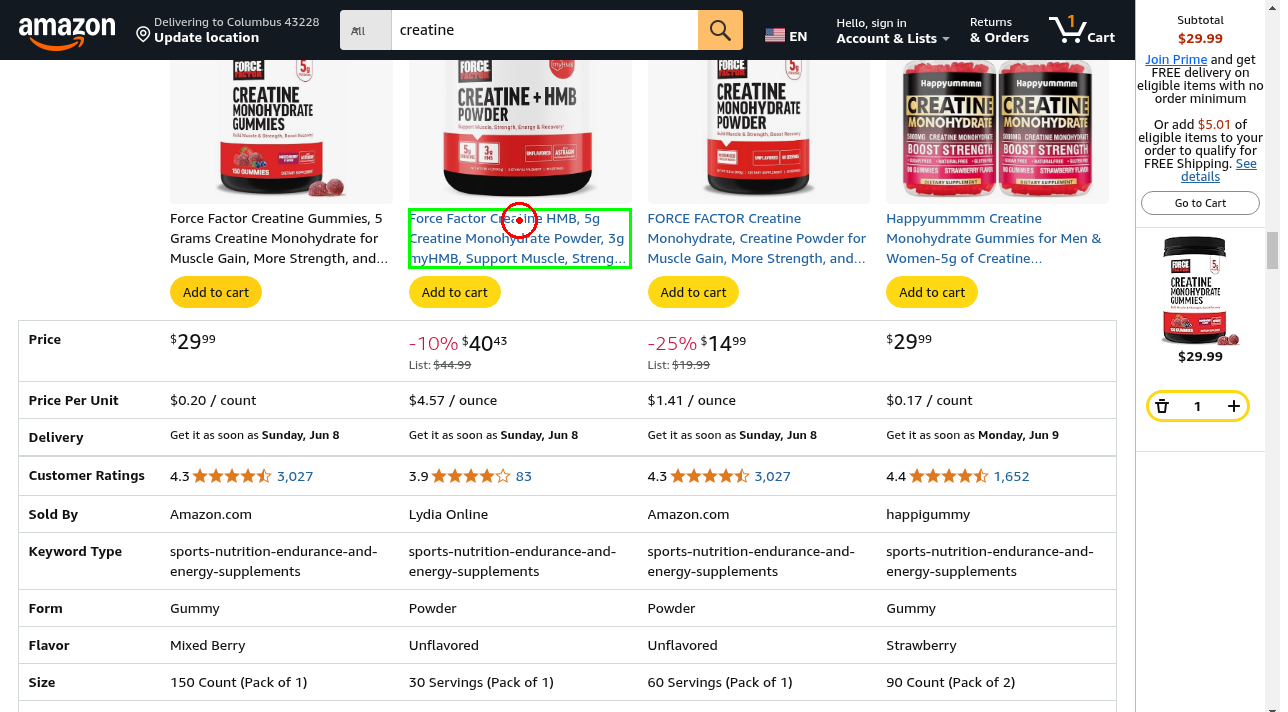

In [21]:
predict_and_show(eval_pool[0])